# Acidentes nas rodovias federais em 2025: quando, onde e por quê?

Análise exploratória dos dados abertos da **Polícia Rodoviária Federal (PRF)**, já limpos e validados nos passos anteriores do projeto (`scripts/01_limpeza.py` e `scripts/04_auditoria_qualidade.py`).

**Perguntas de negócio**
1. Em que momentos os acidentes são mais letais?
2. Onde (estados e rodovias) estão concentrados acidentes e mortes?
3. Quais causas e tipos de acidente mais matam?
4. O que isso sugere para ações de prevenção?

**Métrica principal:** *mortos por 100 acidentes* (letalidade). Ela compara grupos de tamanhos diferentes. Não há dados de tráfego, então o projeto **não** diz qual via é a "mais perigosa", só onde há mais acidentes e mortes.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

AZUL, LARANJA = "#2a78d6", "#eb6834"
TEXTO, TEXTO2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d9d8d4", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ececea", "axes.axisbelow": True,
    "font.size": 10, "text.color": TEXTO, "axes.labelcolor": TEXTO2,
    "xtick.color": TEXTO2, "ytick.color": TEXTO2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
os.makedirs("../docs/img", exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 70)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(f"../docs/img/{nome}.png", dpi=130)
    plt.show()

def resumo(df, coluna, minimo=0):
    """Acidentes, mortos e letalidade (mortos por 100 acidentes) por categoria."""
    r = df.groupby(coluna).agg(acidentes=("id", "count"), mortos=("mortos", "sum"))
    r["mortos_por_100"] = (100 * r["mortos"] / r["acidentes"]).round(1)
    return r[r["acidentes"] >= minimo]

def barras_h(r, coluna, titulo, destaque=3, fmt="{:.1f}"):
    r = r.sort_values(coluna).tail(12)
    cores = [LARANJA if i >= len(r) - destaque else AZUL for i in range(len(r))]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(r) + 1.2))
    ax.barh(r.index.astype(str), r[coluna], color=cores, height=0.65)
    for y, v in enumerate(r[coluna]):
        ax.text(v, y, "  " + fmt.format(v), va="center", fontsize=9, color=TEXTO)
    ax.set_title(titulo); ax.grid(axis="y", visible=False); ax.set_xlim(0, r[coluna].max() * 1.15)
    return ax

## 1. Carga dos dados

In [2]:
df = pd.read_csv("../dados/tratados/acidentes_prf_2025_tratado.csv", parse_dates=["data_hora"])
df["fatal"] = df["classificacao_acidente"].eq("Com Vítimas Fatais")
df["fim_de_semana"] = df["dia_semana"].isin(["Sábado", "Domingo"])

print(f"Registros: {len(df):,}".replace(",", "."))
print(f"Período: {df['data_hora'].min():%d/%m/%Y} a {df['data_hora'].max():%d/%m/%Y}")
print(f"Mortos: {df['mortos'].sum():,} | Feridos: {df['feridos'].sum():,}".replace(",", "."))
print(f"Acidentes fatais: {df['fatal'].sum():,} ({100*df['fatal'].mean():.1f}%)".replace(",", "."))
print(f"Mortos por 100 acidentes: {100*df['mortos'].sum()/len(df):.1f}")

Registros: 72.529
Período: 01/01/2025 a 31/12/2025
Mortos: 6.043 | Feridos: 83.550
Acidentes fatais: 5.210 (7.2%)
Mortos por 100 acidentes: 8.3


## 2. Quando: hora do dia

O **volume** de acidentes e a **letalidade** contam histórias diferentes. O pico de acidentes é no fim da tarde, mas a letalidade é maior na madrugada.

      acidentes  mortos  mortos_por_100
hora                                   
3          1263     208            16.5
4          1595     249            15.6
7          4583     202             4.4
18         5398     434             8.0
19         4646     514            11.1


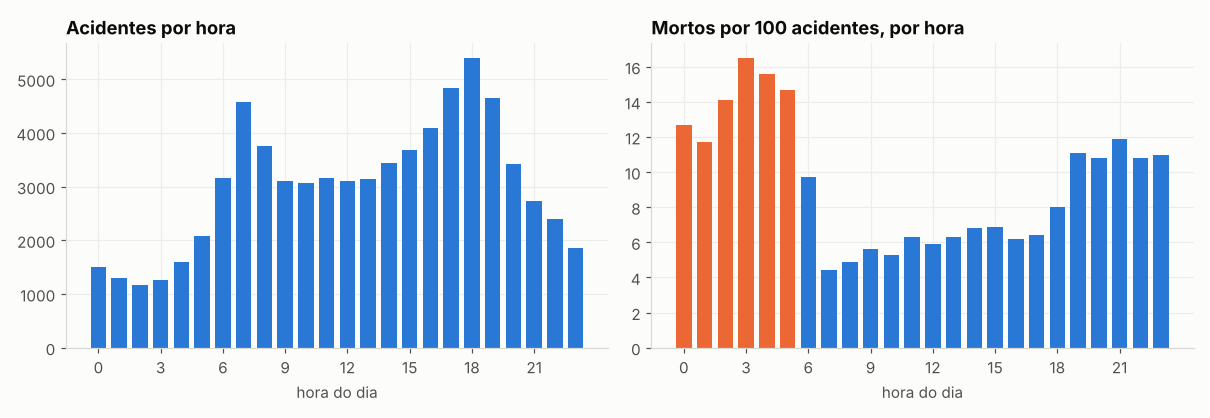

In [3]:
h = resumo(df, "hora")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.bar(h.index, h["acidentes"], color=AZUL, width=0.75)
a1.set_title("Acidentes por hora"); a1.set_xlabel("hora do dia"); a1.set_xticks(range(0, 24, 3))
cor = [LARANJA if x in range(0, 6) else AZUL for x in h.index]
a2.bar(h.index, h["mortos_por_100"], color=cor, width=0.75)
a2.set_title("Mortos por 100 acidentes, por hora"); a2.set_xlabel("hora do dia"); a2.set_xticks(range(0, 24, 3))
salvar("01_hora")
print(h.loc[[3, 4, 7, 18, 19], ["acidentes", "mortos", "mortos_por_100"]])

## 3. Quando: dia da semana

               acidentes  mortos  mortos_por_100
dia_semana                                      
Segunda-feira      10285     747             7.3
Terça-feira         9062     681             7.5
Quarta-feira        9556     711             7.4
Quinta-feira        9405     694             7.4
Sexta-feira        11197     907             8.1
Sábado             11554    1120             9.7
Domingo            11470    1183            10.3


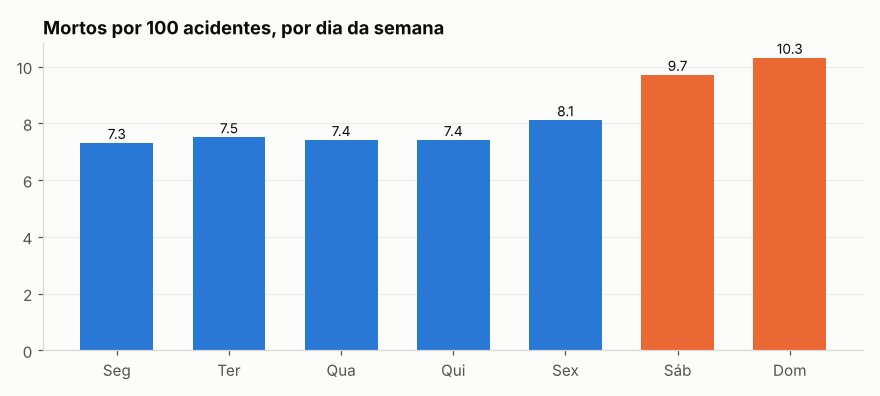

In [4]:
ordem = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado", "Domingo"]
d = resumo(df, "dia_semana").loc[ordem]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar([x[:3] for x in d.index], d["mortos_por_100"], color=[LARANJA if x in ("Sábado", "Domingo") else AZUL for x in d.index], width=0.65)
for i, v in enumerate(d["mortos_por_100"]):
    ax.text(i, v + 0.15, f"{v:.1f}", ha="center", fontsize=9)
ax.set_title("Mortos por 100 acidentes, por dia da semana"); ax.grid(axis="x", visible=False)
salvar("02_dia_semana")
print(d)

### Teste de hipótese: fim de semana é realmente mais letal?

Comparo a proporção de acidentes **fatais** entre fim de semana (sábado e domingo) e dias úteis com o teste qui-quadrado. H0: a proporção é igual nos dois grupos.

In [5]:
tabela = pd.crosstab(df["fim_de_semana"], df["fatal"])
chi2, p, _, _ = stats.chi2_contingency(tabela)
prop = df.groupby("fim_de_semana")["fatal"].mean() * 100
print(tabela)
print(f"\nProporção de acidentes fatais: dias úteis {prop[False]:.1f}% | fim de semana {prop[True]:.1f}%")
print(f"Razão: {prop[True]/prop[False]:.2f}x | qui-quadrado = {chi2:.1f} | p-valor = {p:.2e}")
print("Conclusão: diferença estatisticamente significativa." if p < 0.05 else "Conclusão: sem diferença significativa.")

fatal          False  True 
fim_de_semana              
False          46265   3240
True           21054   1970

Proporção de acidentes fatais: dias úteis 6.5% | fim de semana 8.6%
Razão: 1.31x | qui-quadrado = 95.1 | p-valor = 1.84e-22
Conclusão: diferença estatisticamente significativa.


### Álcool e fim de semana

In [6]:
df["alcool"] = df["causa_acidente"].eq("Ingestão de álcool pelo condutor")
a = df.groupby("dia_semana")["alcool"].agg(["sum", "mean"]).loc[ordem]
a["pct_alcool"] = (100 * a["mean"]).round(1)
print(a[["sum", "pct_alcool"]].rename(columns={"sum": "acidentes_alcool"}))

               acidentes_alcool  pct_alcool
dia_semana                                 
Segunda-feira               307         3.0
Terça-feira                 212         2.3
Quarta-feira                269         2.8
Quinta-feira                286         3.0
Sexta-feira                 398         3.6
Sábado                     1016         8.8
Domingo                    1197        10.4


## 4. Onde: estados

    acidentes  mortos  mortos_por_100
uf                                   
BA       4108     583            14.2
PE       3013     336            11.2
GO       3196     308             9.6
MT       2636     243             9.2
MG       9570     765             8.0
PR       7630     593             7.8


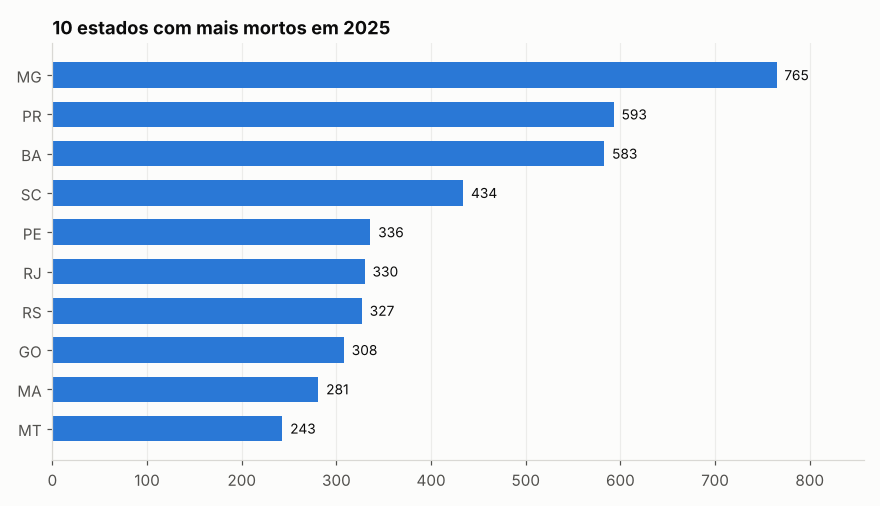

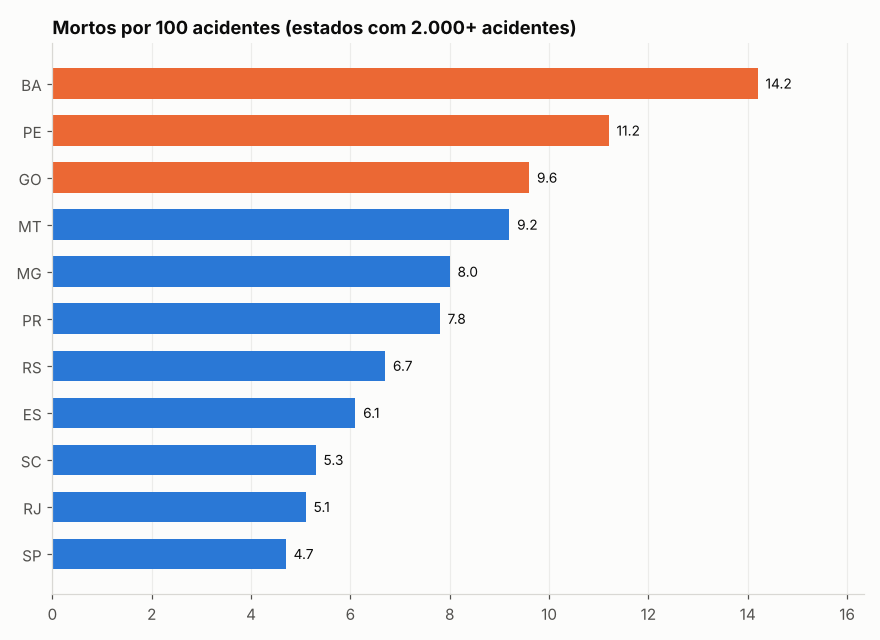

In [7]:
uf = resumo(df, "uf")
top_mortos = uf.sort_values("mortos", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top_mortos.index[::-1], top_mortos["mortos"][::-1], color=AZUL, height=0.65)
for y, v in enumerate(top_mortos["mortos"][::-1]):
    ax.text(v, y, f"  {v}", va="center", fontsize=9)
ax.set_title("10 estados com mais mortos em 2025"); ax.grid(axis="y", visible=False); ax.set_xlim(0, top_mortos["mortos"].max() * 1.12)
salvar("03_uf_mortos")

grandes = resumo(df, "uf", minimo=2000)
barras_h(grandes, "mortos_por_100", "Mortos por 100 acidentes (estados com 2.000+ acidentes)", destaque=3)
salvar("04_uf_letalidade")
print(grandes.sort_values("mortos_por_100", ascending=False).head(6))

### Trechos (BR + UF) com mais mortos

In [8]:
trecho = df[df["br"].notna()].assign(trecho=lambda x: "BR-" + x["br"].astype(int).astype(str) + " " + x["uf"])
t = resumo(trecho, "trecho", minimo=300).sort_values("mortos", ascending=False).head(10)
print(t)

           acidentes  mortos  mortos_por_100
trecho                                      
BR-381 MG       2845     158             5.6
BR-40 MG        1972     153             7.8
BR-101 BA        956     153            16.0
BR-116 SP       3249     152             4.7
BR-277 PR       2157     152             7.0
BR-101 SC       4222     147             3.5
BR-101 RJ       2415     138             5.7
BR-116 BA       1038     126            12.1
BR-116 MG       1412     124             8.8
BR-101 ES       2084     123             5.9


## 5. Por quê: causas e tipos de acidente

                                                           acidentes  mortos  mortos_por_100
causa_acidente                                                                              
Ausência de reação do condutor                                 11469     855             7.5
Reação tardia ou ineficiente do condutor                       10799     597             5.5
Acessar a via sem observar a presença dos outros veículos       7097     421             5.9
Condutor deixou de manter distância do veículo da frente        4413      89             2.0
Velocidade Incompatível                                         4088     470            11.5


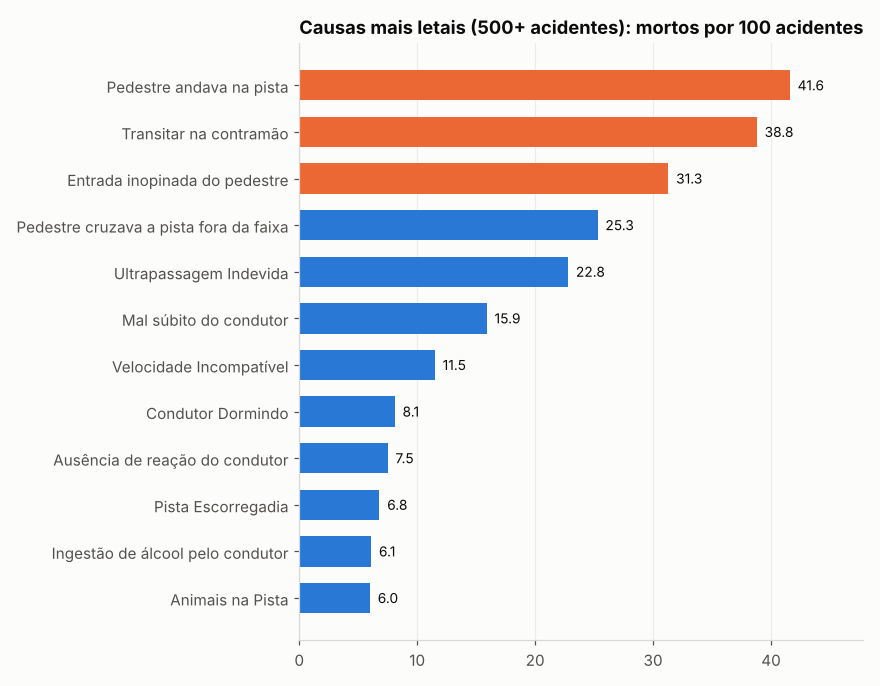

In [9]:
c = resumo(df, "causa_acidente", minimo=500)
barras_h(c, "mortos_por_100", "Causas mais letais (500+ acidentes): mortos por 100 acidentes", destaque=3)
salvar("05_causas_letalidade")
print(c.sort_values("acidentes", ascending=False).head(5))

                                acidentes  mortos  mortos_por_100
tipo_acidente                                                    
Colisão frontal                      4739    1863            39.3
Atropelamento de Pedestre            3057     919            30.1
Colisão lateral sentido oposto       2152     255            11.8
Saída de leito carroçável           10209     700             6.9


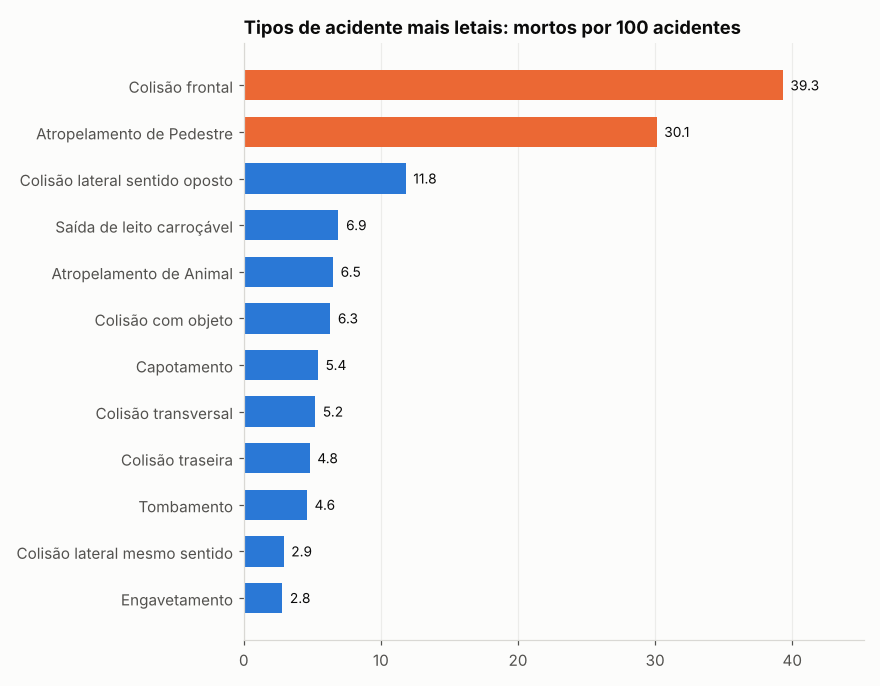

In [10]:
tp = resumo(df, "tipo_acidente", minimo=500)
barras_h(tp, "mortos_por_100", "Tipos de acidente mais letais: mortos por 100 acidentes", destaque=2)
salvar("06_tipo_letalidade")
print(tp.sort_values("mortos_por_100", ascending=False).head(4))

In [11]:
alvo = ["Colisão frontal", "Atropelamento de Pedestre"]
sel = df["tipo_acidente"].isin(alvo)
print(f"Colisão frontal + atropelamento de pedestre: {100*sel.mean():.1f}% dos acidentes e {100*df.loc[sel, 'mortos'].sum()/df['mortos'].sum():.1f}% dos mortos")

Colisão frontal + atropelamento de pedestre: 10.7% dos acidentes e 46.0% dos mortos


## 6. Clima: um resultado contraintuitivo

À primeira vista, chuva tem **menos** mortos por acidente que tempo bom. Antes de concluir algo, vale ver se isso muda quando se controla o período do dia.

In [12]:
cl = resumo(df, "grupo_clima")
print(cl.sort_values("acidentes", ascending=False))
print()
cruz = df.pivot_table(index="grupo_clima", columns="fase_dia", values="mortos", aggfunc=lambda s: round(100 * s.sum() / len(s), 1))
print("Mortos por 100 acidentes, por clima e período do dia:")
print(cruz)

                    acidentes  mortos  mortos_por_100
grupo_clima                                          
Bom tempo               50576    4234             8.4
Nublado                 11435     955             8.4
Chuva                    8860     655             7.4
Não informado            1000     115            11.5
Baixa visibilidade        553      74            13.4
Outros                    105      10             9.5

Mortos por 100 acidentes, por clima e período do dia:
fase_dia            Amanhecer  Anoitecer  Plena Noite  Pleno dia
grupo_clima                                                     
Baixa visibilidade       14.2       25.0         18.8        1.5
Bom tempo                15.0        7.9         11.9        6.1
Chuva                     9.4        6.0          9.4        5.9
Nublado                  12.5        6.0         11.9        5.3
Não informado            14.0        9.5         13.0        5.0
Outros                   14.3        0.0          9.7     

## 7. Evolução mensal

mes          1     2     3     4     5     6     7     8     9     10    11    12
acidentes  5528  5287  5960  5786  6096  6122  6238  6246  6017  6252  6209  6788
mortos      418   412   462   495   574   528   536   554   500   494   498   572


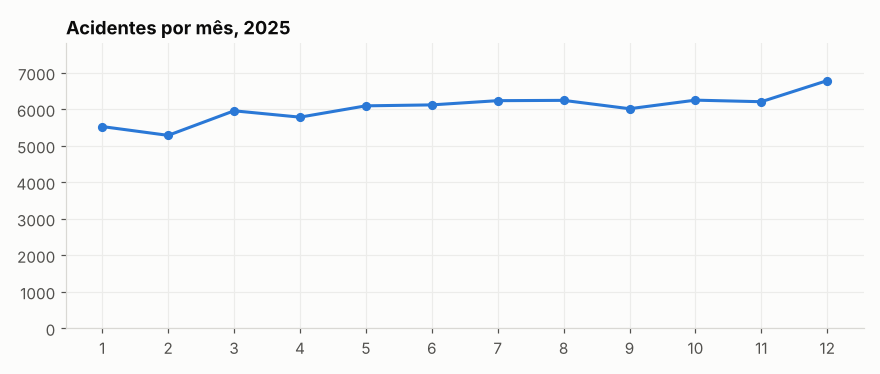

In [13]:
m = resumo(df, "mes")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(m.index, m["acidentes"], color=AZUL, lw=2, marker="o", ms=5)
ax.set_title("Acidentes por mês, 2025"); ax.set_xticks(range(1, 13)); ax.set_ylim(0, m["acidentes"].max() * 1.15)
salvar("07_mensal")
print(m[["acidentes", "mortos"]].T)

## 8. Foco em São Paulo

In [14]:
sp = df[df["uf"] == "SP"]
print(f"SP: {len(sp):,} acidentes, {sp['mortos'].sum()} mortos, {100*sp['mortos'].sum()/len(sp):.1f} mortos por 100 acidentes".replace(",", "."))
print()
print(resumo(sp, "municipio").sort_values("acidentes", ascending=False).head(8))
print()
print(resumo(sp, "causa_acidente").sort_values("acidentes", ascending=False).head(5))

SP: 4.683 acidentes. 221 mortos. 4.7 mortos por 100 acidentes

                       acidentes  mortos  mortos_por_100
municipio                                               
GUARULHOS                    742      22             3.0
SAO JOSE DOS CAMPOS          413      13             3.1
SAO PAULO                    316      23             7.3
UBATUBA                      256       8             3.1
SAO JOSE DO RIO PRETO        206      10             4.9
ATIBAIA                      181       9             5.0
TAUBATE                      168      10             6.0
MAIRIPORA                    159       4             2.5

                                                          acidentes  mortos  mortos_por_100
causa_acidente                                                                             
Reação tardia ou ineficiente do condutor                       1054      26             2.5
Ausência de reação do condutor                                  920      43             4.

## 9. Conclusões

1. **Madrugada é o horário mais letal.** Às 3h morrem 16,5 pessoas a cada 100 acidentes, contra 4,4 às 7h. O pico de *volume* é às 18h (5.398 acidentes), mas com letalidade bem menor (8,0).
2. **Fim de semana é mais letal, e a diferença é estatisticamente significativa.** 8,6% dos acidentes de sábado e domingo são fatais, contra 6,5% nos dias úteis (1,31x; qui-quadrado, p < 0,001). O álcool explica parte: responde por 10,4% dos acidentes de domingo, contra 2,3% a 3,6% de terça a sexta.
3. **Poucos tipos de acidente concentram as mortes.** Colisão frontal e atropelamento de pedestre são cerca de 11% dos acidentes, mas quase metade dos mortos. As causas mais letais são "pedestre andava na pista" e "transitar na contramão" (acima de 38 mortos por 100 acidentes).
4. **Os estados diferem muito em letalidade.** MG tem o maior número de mortos (765), mas a Bahia chega a 14,2 mortos por 100 acidentes, contra 5,3 em SC. A BR-101 na Bahia tem 16,0.
5. **Em São Paulo**, são 4.683 acidentes, 221 mortos e 4,7 mortos por 100 acidentes. Guarulhos lidera em volume (742) com letalidade baixa (3,0); a capital tem menos acidentes (316), mas letalidade maior (7,3).
6. **Chuva não aumenta a letalidade nesta base.** Mesmo separando por período do dia, acidentes sob chuva têm letalidade igual ou menor que os de tempo bom. Hipótese a investigar: velocidades menores sob chuva. Os dados não permitem confirmar.

### Recomendações (hipóteses para ação, não conclusões causais)
- Concentrar fiscalização de alcoolemia em **noites e madrugadas de sexta a domingo**.
- Priorizar **separação física de pistas e travessias para pedestres** nos trechos com mais colisões frontais e atropelamentos.
- Olhar o **ranking de letalidade, e não só o de volume**, ao distribuir recursos entre estados.

### Limitações
- **Sem dados de tráfego (veículos por km):** não dá para afirmar que uma rodovia é mais perigosa, só que concentra mais acidentes ou mortes.
- **Só um ano (2025)**, sem tendência histórica.
- A base cobre **rodovias federais** e só acidentes registrados pela PRF.
- Campos `pessoas` e `ignorados` têm inconsistências (ver `docs/relatorio_qualidade.md`), por isso as métricas usam `mortos` e `feridos`.
- Correlação não é causa: os cortes por hora, dia e clima não isolam o efeito de cada fator.